# Case Study 25 — Monthly Digital-Payments Volume: Describing a Time Series and Building an Honest Baseline

**Trend and seasonality · decomposition · rolling statistics · autocorrelation (ACF/PACF) · stationarity and the ADF test ·
differencing · outliers and structural shocks · baseline forecasts (naive, seasonal naive, drift, Holt-Winters, SARIMA, regression) ·
rolling-origin evaluation · MAPE and MASE · prediction intervals and their coverage**

| | |
|---|---|
| **Domain** | Payments / finance: capacity and budget planning |
| **Stakeholders** | Head of Payments Finance, Capacity Planning |
| **Difficulty** | Intermediate |
| **Importance** | 🟡 GOOD TO HAVE |
| **Builds on** | Case 01 (descriptives), Case 06 (regression), Case 10 (log transforms) |
| **Data** | 108 months (Jan 2016 to Dec 2024) of transaction volume, in millions |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual company data.
> See `src/generate_data.py`. The next 12 months (2025) and the true components are kept in teaching-only files that the notebook
> opens only in Section 12. Sections 4 to 11 use only what a real analyst would have on the forecast date.

**What you will learn**

1. How to describe a time series in terms of **trend, seasonality, calendar effects, shocks and noise**.
2. Why ordinary statistics (and ordinary random splits) break when observations are **autocorrelated**.
3. How to test for and remove **non-stationarity** (ADF, differencing, logs).
4. How to build **baseline forecasts**, evaluate them honestly with **rolling-origin** tests, and say how uncertain they are.

## Section 1 — Business context

Payments Finance must submit next year's capacity and budget plan. The Head of Finance writes:

> *"Volume has grown every year. Take the 2024 total and add 20%, that has worked before. Capacity planning also wants to know:
> is there a seasonal pattern we should staff for, what did COVID do to our numbers, and how wrong could the forecast be?"*

## Section 2 — Business questions

1. What does the history look like: trend, seasonality, shocks?
2. Can we trust ordinary statistics (means, correlations, regressions) on this series as it stands?
3. What is a defensible baseline forecast for the next 12 months, and what must a fancier model beat?
4. How uncertain is the forecast, and are the stated intervals honest?
5. Is "last year plus 20%" a sensible rule?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Shape of the history | Decompose into trend, seasonal, remainder | Log scale, STL decomposition, rolling statistics |
| 2 | Can we trust ordinary statistics? | Is the series stationary? Is there autocorrelation? | ADF test, differencing, ACF/PACF |
| 3 | Baseline forecast | Which simple model forecasts best out-of-sample? | Naive, seasonal naive, drift, Holt-Winters, SARIMA, trend-seasonal regression |
| 4 | Uncertainty | Do the 80% / 95% intervals contain the truth that often? | Rolling-origin interval coverage |
| 5 | The 20% rule | Is a fixed growth rate consistent with the data? | Year-over-year growth |

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "25_digital_payments_time_series"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
warnings.filterwarnings("ignore")

## Section 4 — Load the data and look at it

108 months, Jan 2016 to Dec 2024; missing 0; gaps in the monthly index: 0


,count,mean,std,min,25%,50%,75%,max
transactions_m,108.0000,146.6706,106.4217,19.5900,53.0825,110.8700,221.0775,388.8800


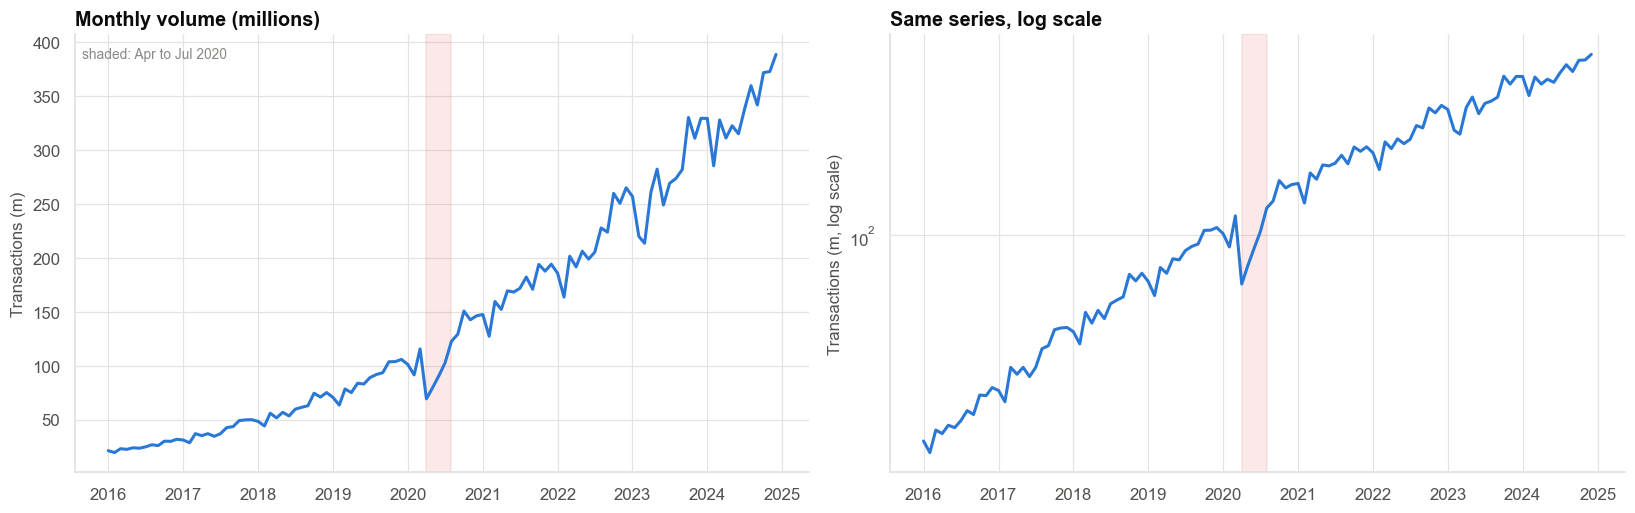

In [2]:
d = pd.read_csv(PATHS["data"] / "monthly_volume.csv", parse_dates=["month"]).set_index("month")
y = d["transactions_m"]
print(f"{len(y)} months, {y.index.min():%b %Y} to {y.index.max():%b %Y}; missing {y.isna().sum()}; gaps in the monthly index: {(y.index.to_series().diff().dropna().dt.days > 31).sum()}")
display(y.describe().to_frame().T)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
axes[0].plot(y.index, y, color=PRIMARY, lw=2); axes[0].set(title="Monthly volume (millions)", ylabel="Transactions (m)")
axes[1].semilogy(y.index, y, color=PRIMARY, lw=2); axes[1].set(title="Same series, log scale", ylabel="Transactions (m, log scale)")
for ax in axes:
    ax.axvspan(pd.Timestamp("2020-04-01"), pd.Timestamp("2020-07-31"), color=COLORS["red"], alpha=0.12)
add_note(axes[0], "shaded: Apr to Jul 2020", "upper left")
fig.tight_layout(); save_fig(fig, "fig01_series", PATHS["figures"]); plt.show()

**Observation.** 108 consecutive months, no gaps or missing values. Volume rises from about 20 million a month to about 390 million
(mean 147, median 111: a right-skewed, trending series). On the log scale the growth is close to a straight line that flattens
slowly. There is a sharp, short dip from April to July 2020 (the shaded area) and a single-month dip in March 2023.

**Interpretation.** The mean and standard deviation of this series are not meaningful descriptions: they depend on which years you include.

## Section 5 — Method selection

**Why time series need their own methods.** Observations in time are not independent: this month resembles last month. Ordinary
formulas for standard errors assume independence and are too optimistic. A random train/test split lets the model see the future.
Always split **by time**, and evaluate by forecasting from several past origins ("rolling origin").

**Additive or multiplicative?** If the seasonal swings grow with the level, the series is multiplicative; taking logs turns it into an additive one.

**Decomposition.** y = trend + seasonal + remainder (on logs). STL (seasonal-trend decomposition by LOESS) handles changing seasonality and is robust to outliers when run in robust mode.

**Stationarity.** A series is stationary when its mean, variance and autocorrelation do not depend on time. Most forecasting models need stationarity after transformations: logs for variance, differencing for trend, seasonal differencing for seasonality. The **augmented Dickey-Fuller (ADF) test** has H0 "unit root (non-stationary)"; a small p-value supports stationarity.

**Baselines worth beating.** Naive (last value), seasonal naive (same month last year), drift. A complex model that cannot beat seasonal naive is not worth deploying.

**Metrics.** MAPE (percentage error, easy to explain) and **MASE** (error scaled by the in-sample seasonal naive error; below 1 means better than seasonal naive).

## Section 6 — Decomposition and rolling statistics

month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
seasonal effect (log points),0.0052,-0.1384,0.0392,-0.0363,0.0120,-0.0578,-0.0132,0.0268,-0.0189,0.0893,0.0390,0.0550
multiplier vs average month,1.0052,0.8707,1.0400,0.9643,1.0120,0.9438,0.9868,1.0272,0.9813,1.0935,1.0398,1.0565


Trend growth, year over year: 52% in Jan 2017, 19% in Dec 2024
Months with remainder more than 3 robust SDs from normal: ['Apr 2020', 'May 2020', 'Jun 2020', 'Jul 2020', 'Aug 2020', 'Jun 2021', 'Mar 2023', 'Aug 2023']


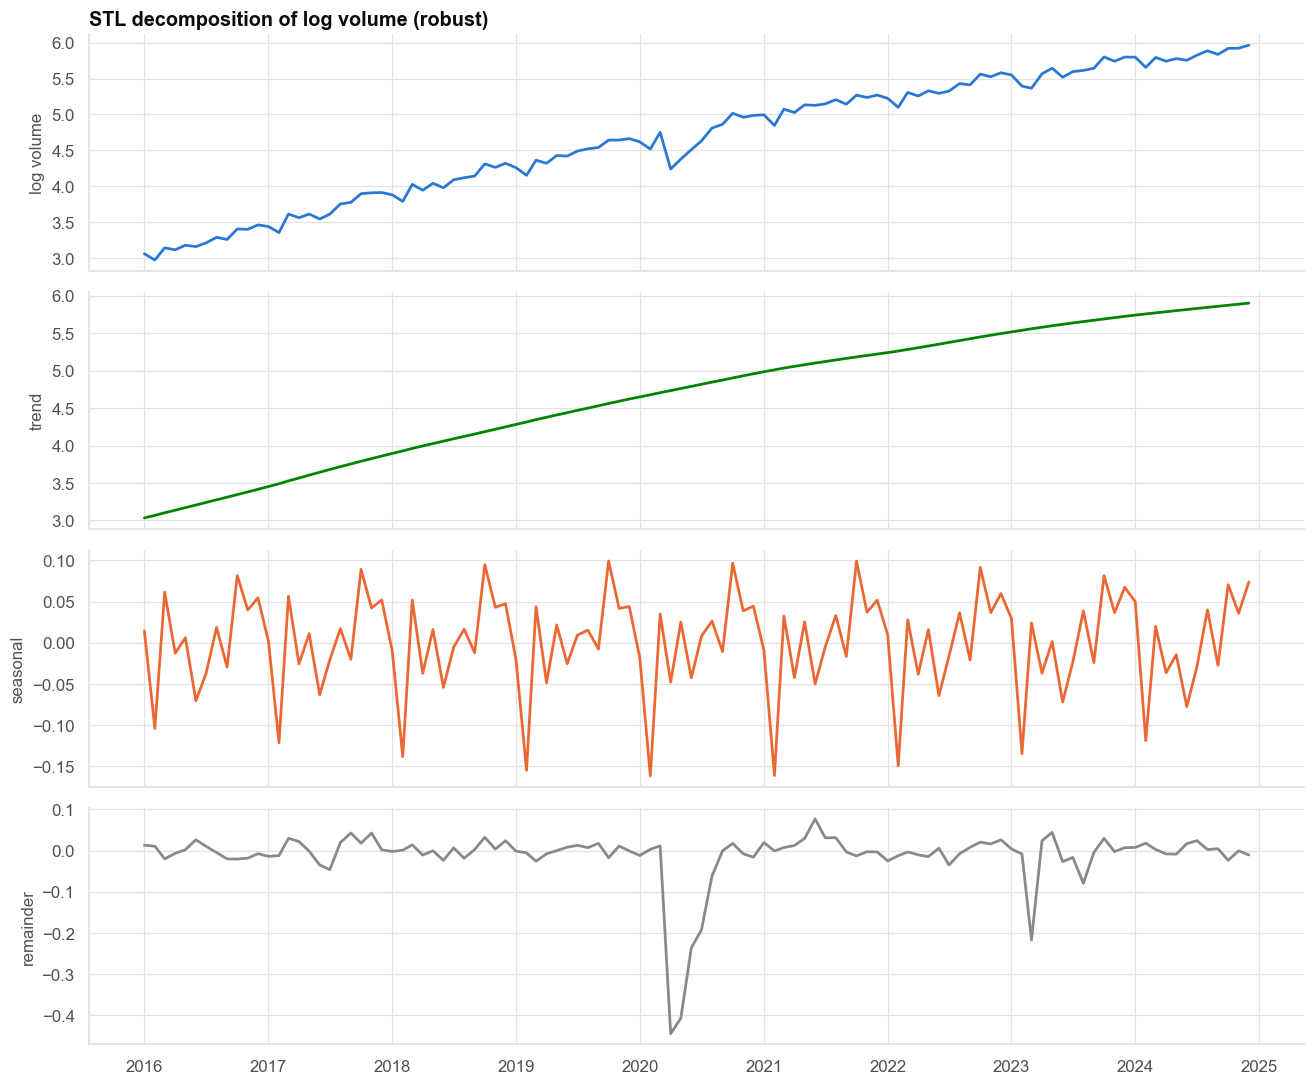

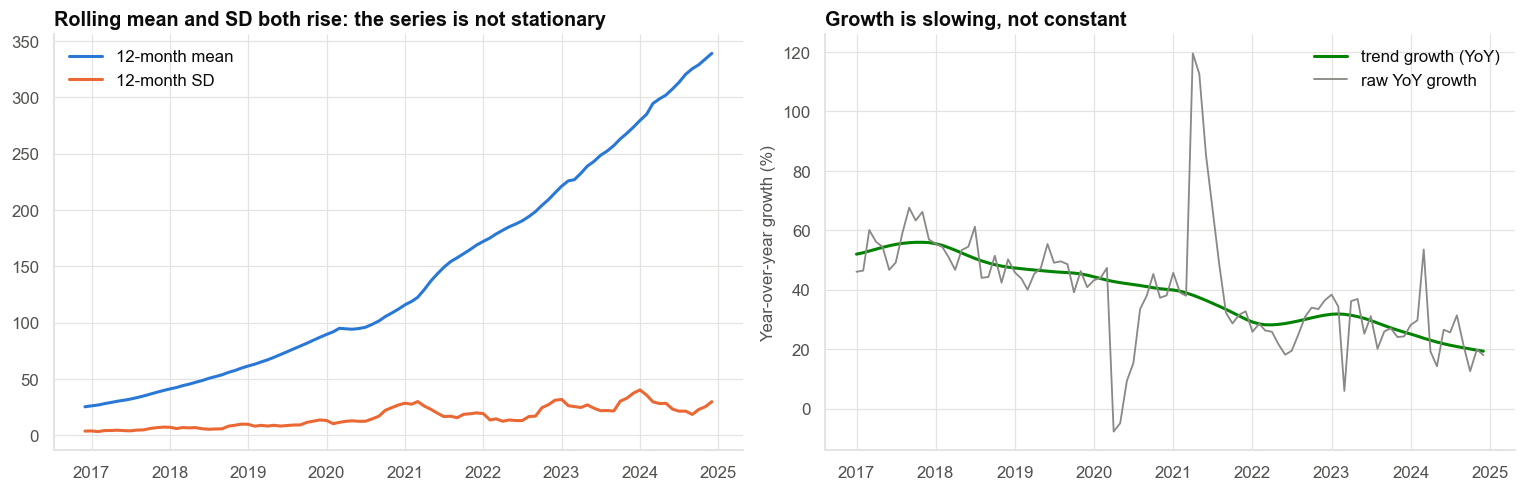

In [3]:
ly = np.log(y)
stl = STL(ly, period=12, robust=True).fit()
comp = pd.DataFrame({"log volume": ly, "trend": stl.trend, "seasonal": stl.seasonal, "remainder": stl.resid})
seas_month = comp["seasonal"].groupby(comp.index.month).mean()
seas_tbl = pd.DataFrame({"seasonal effect (log points)": seas_month, "multiplier vs average month": np.exp(seas_month)})
seas_tbl.index = pd.Index([pd.Timestamp(2000, m, 1).strftime("%b") for m in seas_tbl.index], name="month")
save_table(seas_tbl, "seasonal_pattern", PATHS["tables"])
display(seas_tbl.T)
growth = (np.exp(comp["trend"].diff(12)) - 1).dropna()
yoy = y.pct_change(12).dropna()
print(f"Trend growth, year over year: {growth.iloc[0]:.0%} in {growth.index[0]:%b %Y}, {growth.iloc[-1]:.0%} in {growth.index[-1]:%b %Y}")
rem_sd = comp["remainder"].std(); out = comp[np.abs(comp["remainder"] - comp["remainder"].median()) > 3 * 1.4826 * (comp["remainder"] - comp["remainder"].median()).abs().median()]
print("Months with remainder more than 3 robust SDs from normal:", [f"{i:%b %Y}" for i in out.index])
roll = pd.DataFrame({"12-month mean": y.rolling(12).mean(), "12-month SD": y.rolling(12).std(), "12-month CV": y.rolling(12).std() / y.rolling(12).mean()}).dropna()

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, c, col in zip(axes, comp.columns, [PRIMARY, COLORS["green"], COLORS["orange"], INK_MUTED]):
    ax.plot(comp.index, comp[c], color=col, lw=1.8); ax.set_ylabel(c)
axes[0].set_title("STL decomposition of log volume (robust)")
fig.tight_layout(); save_fig(fig, "fig02_decomposition", PATHS["figures"]); plt.show()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].plot(roll.index, roll["12-month mean"], color=PRIMARY, lw=2, label="12-month mean"); axes[0].plot(roll.index, roll["12-month SD"], color=HIGHLIGHT, lw=2, label="12-month SD")
axes[0].legend(frameon=False); axes[0].set(title="Rolling mean and SD both rise: the series is not stationary")
axes[1].plot(growth.index, 100 * growth, color=COLORS["green"], lw=2, label="trend growth (YoY)"); axes[1].plot(yoy.index, 100 * yoy, color=INK_MUTED, lw=1.2, label="raw YoY growth")
axes[1].set(ylabel="Year-over-year growth (%)", title="Growth is slowing, not constant"); axes[1].legend(frameon=False)
fig.tight_layout(); save_fig(fig, "fig03_rolling_growth", PATHS["figures"]); plt.show()

**Observation.**
- **Trend:** year-over-year trend growth falls from **52%** (Jan 2017) to **19%** (Dec 2024). Calendar-year volume growth was 57%, 50%, 46%, 29% (COVID), 51% (rebound), 27%, 27% and 24%. Growth is slowing, not constant.
- **Seasonality:** the multiplier on an average month is about **1.09 in October**, 1.04 in November and 1.06 in December, and **0.87 in February** (a short month).
  March is high (1.04, fiscal year end). The swing from the lowest to the highest month is about 25%.
- **Remainder:** the STL remainder is small except for April to August 2020, June 2021, March 2023 and August 2023. The robust rule also flags two months that are ordinary noise (Jun 2021, Aug 2023); a flag is a prompt to look, not a verdict.
- **Rolling statistics:** the 12-month mean and SD both rise steadily, so the raw series is not stationary.

**Interpretation.** The history is a slowing exponential trend, a stable seasonal pattern, and two real shocks. Because the STL seasonal component includes the calendar (number of days) effect,
the February dip (−0.14 log points) is deeper than February's "pure" seasonal effect: that is a short month, not a quiet one.

## Section 7 — Stationarity and autocorrelation

We test the raw series, the log, the log with a first difference, and the log with first and seasonal differences. Then we look at the autocorrelation function (ACF) of
the remainder after differencing.

,ADF statistic,p-value,lags used,observations,stationary at 5%?
series,,,,,
raw volume,4.9505,1.0000,11,96,False
log volume,-2.8588,0.0504,13,94,False
"log, first difference",-3.3106,0.0144,11,95,True
"log, seasonal difference (12)",-1.6888,0.4369,12,83,False
"log, first + seasonal difference",-4.5281,0.0002,11,83,True


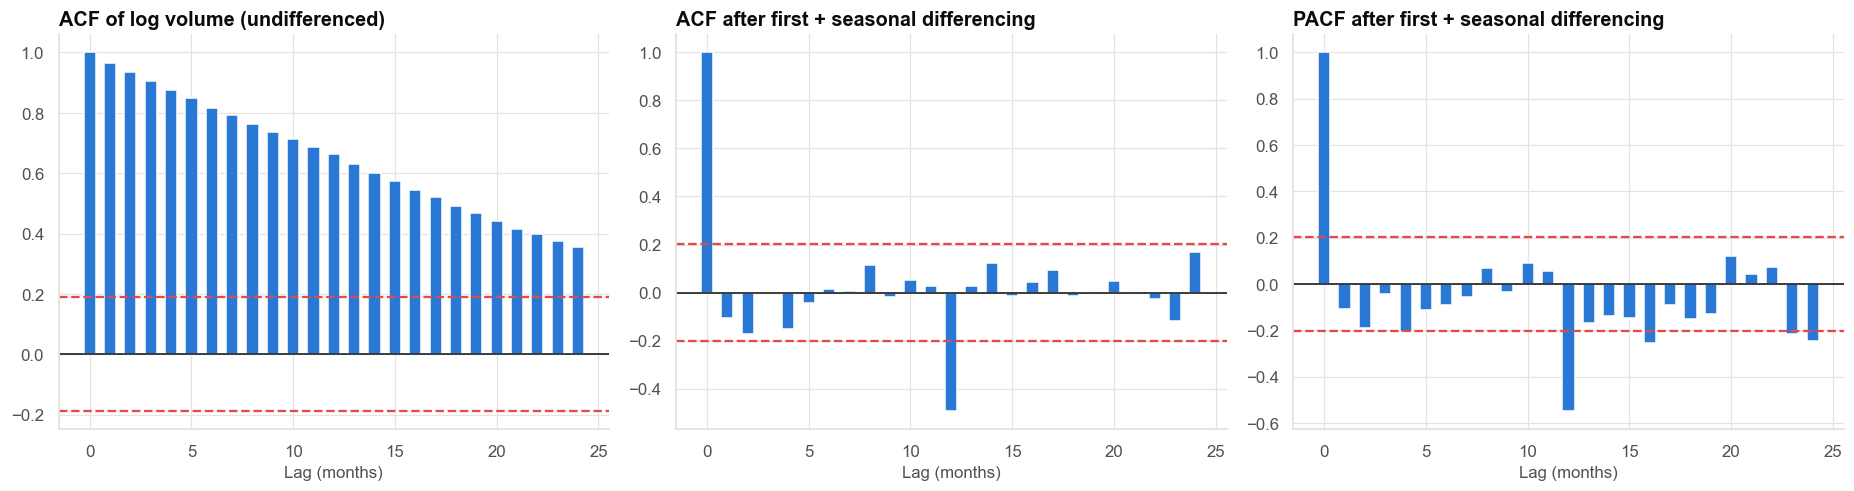

Lag-1 autocorrelation of the STL remainder: 0.61;  Ljung-Box p-value (12 lags): 1.6e-08


In [4]:
cov_mask = ~((y.index >= "2020-04-01") & (y.index <= "2020-07-01")) & (y.index != "2023-03-01")
def adf_row(name, s):
    s = s.dropna(); r = adfuller(s, autolag="AIC")
    return {"series": name, "ADF statistic": r[0], "p-value": r[1], "lags used": r[2], "observations": r[3], "stationary at 5%?": r[1] < 0.05}
tests = pd.DataFrame([adf_row("raw volume", y), adf_row("log volume", ly), adf_row("log, first difference", ly.diff()),
                      adf_row("log, seasonal difference (12)", ly.diff(12)), adf_row("log, first + seasonal difference", ly.diff().diff(12))]).set_index("series")
save_table(tests, "adf_tests", PATHS["tables"]); display(tests)
dd = ly.diff().diff(12).dropna()
lag_acf = acf(dd, nlags=24); lag_pacf = pacf(dd, nlags=24)
raw_acf = acf(ly, nlags=24)
ci = 1.96 / np.sqrt(len(dd))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, vals, ttl, cl in [(axes[0], raw_acf, "ACF of log volume (undifferenced)", 1.96 / np.sqrt(len(ly))), (axes[1], lag_acf, "ACF after first + seasonal differencing", ci), (axes[2], lag_pacf, "PACF after first + seasonal differencing", ci)]:
    ax.bar(range(len(vals)), vals, color=PRIMARY, width=0.6); ax.axhline(0, color=INK, lw=1); ax.axhline(cl, color=COLORS["red"], ls="--"); ax.axhline(-cl, color=COLORS["red"], ls="--")
    ax.set(title=ttl, xlabel="Lag (months)")
fig.tight_layout(); save_fig(fig, "fig04_acf", PATHS["figures"]); plt.show()
# Why independence formulas fail: the standard error of the mean of the first-differenced remainder
r1 = acf(comp["remainder"], nlags=1)[1]
print(f"Lag-1 autocorrelation of the STL remainder: {r1:.2f};  Ljung-Box p-value (12 lags): {sm.stats.acorr_ljungbox(comp['remainder'], lags=[12])['lb_pvalue'].iloc[0]:.2g}")

**Observation.** ADF p-values (H0: non-stationary): raw volume **1.00**, log volume **0.05** (borderline, not stationary at 5%), log first difference **0.014**,
log seasonal difference 0.44, and log first plus seasonal difference **0.0002**. After the first and seasonal differences the ACF shows few significant spikes. The remainder from STL still has a lag-1 autocorrelation of
**0.61** (Ljung-Box p = 1.6 × 10⁻⁸ over 12 lags).

**Interpretation.**
- Differencing once removes the trend (p = 0.014); differencing seasonally alone does not (p = 0.44); both together give a clearly stationary series.
- The autocorrelation is the reason ordinary formulas are unsafe here: standard errors computed as if the 108 months were independent are too small, and a random train/test split would leak neighbouring months.
- A borderline ADF p-value (0.05) is a reminder that the test has low power with a trend and a few shocks: look at the plots too.

## Section 8 — Baseline forecasts and honest evaluation

We forecast the log volume 12 months ahead from **rolling origins**: train on data up to month T, forecast T+1 to T+12, move T forward. Origins are the last 36 months of history,
every 3 months (so 9 origins; the final one ends exactly at the end of the data). All models see only the data before their origin. We then convert back from logs.

Models:

| Model | Idea |
|---|---|
| Naive | Every future month = last observed month |
| Seasonal naive | Each future month = same month last year |
| Seasonal naive + drift | Same month last year × the average annual growth of the last year |
| Holt-Winters | Exponential smoothing with damped trend and additive seasonality on logs |
| SARIMA | (1,1,1)(0,1,1,12) on logs |
| Trend + season regression | log volume ~ trend + trend² + month dummies, with dummies for the known COVID months and the outage |

9 forecast origins, each forecasting 12 months ahead (origin months: Dec 2021, Mar 2022, Jun 2022, Sep 2022, Dec 2022, Mar 2023, Jun 2023, Sep 2023, Dec 2023)


,MAPE (%),MASE,bias (%)
model,,,
Trend + season regression,4.1573,0.3357,1.4404
Holt-Winters (damped),6.6783,0.5739,-1.3215
Seasonal naive + drift,8.7062,0.6980,4.9848
SARIMA,9.8196,0.8403,8.0435
Naive,14.3785,1.2826,-12.1252
Seasonal naive,21.3802,1.8484,-21.3802


nominal,0.8000,0.9500
model,,
SARIMA,0.9167,0.9630
Trend + season regression,0.8796,0.9537


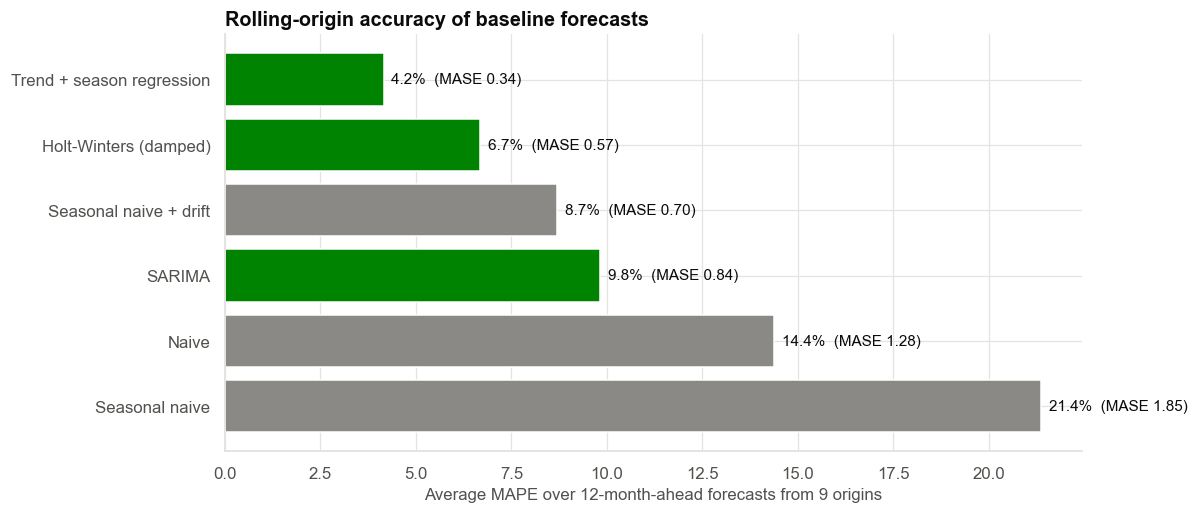

In [5]:
H = 12
covid_months = pd.to_datetime(["2020-04-01", "2020-05-01", "2020-06-01", "2020-07-01"])
def design(index, t0=0):
    X = pd.DataFrame({"t": (np.arange(len(index)) + t0) / 12.0}, index=index); X["t2"] = X["t"] ** 2
    X["covid"] = index.isin(covid_months).astype(int); X["outage"] = (index == pd.Timestamp("2023-03-01")).astype(int)
    return pd.concat([X, pd.get_dummies(index.month, prefix="m", drop_first=True).set_index(index).astype(float)], axis=1)

def forecast_all(train_y):
    ly_ = np.log(train_y); idx = pd.date_range(train_y.index[-1] + pd.offsets.MonthBegin(), periods=H, freq="MS")
    out = {}
    out["Naive"] = pd.Series(np.repeat(ly_.iloc[-1], H), idx)
    out["Seasonal naive"] = pd.Series(ly_.iloc[-12:].to_numpy(), idx)
    annual = ly_.iloc[-12:].mean() - ly_.iloc[-24:-12].mean()
    out["Seasonal naive + drift"] = pd.Series(ly_.iloc[-12:].to_numpy() + annual, idx)
    hw = ExponentialSmoothing(ly_, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12, initialization_method="estimated").fit()
    out["Holt-Winters (damped)"] = pd.Series(hw.forecast(H).to_numpy(), idx)
    sa = SARIMAX(ly_, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12), enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    fc = sa.get_forecast(H); sarima_sd = fc.se_mean.to_numpy()
    out["SARIMA"] = pd.Series(fc.predicted_mean.to_numpy(), idx)
    Xtr = design(ly_.index); Xte = design(idx, t0=len(ly_))
    ols = sm.OLS(ly_, sm.add_constant(Xtr)).fit(); pr = ols.get_prediction(sm.add_constant(Xte, has_constant="add")).summary_frame(alpha=0.05)
    out["Trend + season regression"] = pd.Series(pr["mean"].to_numpy(), idx)
    sds = {"SARIMA": sarima_sd, "Trend + season regression": ((pr["obs_ci_upper"] - pr["mean"]) / 1.96).to_numpy()}
    return out, sds

origins = list(range(len(y) - 36, len(y) - H + 1, 3))
rows, cover = [], []
scale_cache = {}
for o in origins:
    tr = y.iloc[:o]; te = y.iloc[o:o + H]
    fc, sds = forecast_all(tr)
    mase_scale = np.mean(np.abs(tr.iloc[12:].to_numpy() - tr.iloc[:-12].to_numpy()))
    for name, f in fc.items():
        pred = np.exp(f.to_numpy())
        rows.append({"origin": tr.index[-1], "model": name, "MAPE (%)": 100 * np.mean(np.abs(pred - te.to_numpy()) / te.to_numpy()),
                     "MASE": np.mean(np.abs(pred - te.to_numpy())) / mase_scale, "bias (%)": 100 * np.mean((pred - te.to_numpy()) / te.to_numpy())})
    for name, sd in sds.items():
        for lvl, z in [(0.8, 1.2816), (0.95, 1.96)]:
            lo, hi = np.exp(fc[name].to_numpy() - z * sd), np.exp(fc[name].to_numpy() + z * sd)
            cover.append({"model": name, "nominal": lvl, "origin": tr.index[-1], "covered": np.mean((te.to_numpy() >= lo) & (te.to_numpy() <= hi))})
res = pd.DataFrame(rows)
summ = res.groupby("model")[["MAPE (%)", "MASE", "bias (%)"]].mean().sort_values("MAPE (%)")
save_table(summ, "rolling_origin_accuracy", PATHS["tables"]); save_table(res, "rolling_origin_detail", PATHS["tables"], index=False)
cv = pd.DataFrame(cover).groupby(["model", "nominal"])["covered"].mean().unstack()
save_table(cv, "interval_coverage", PATHS["tables"])
print(f"{len(origins)} forecast origins, each forecasting {H} months ahead (origin months: {', '.join(f'{y.index[o - 1]:%b %Y}' for o in origins)})")
display(summ); display(cv)
fig, ax = plt.subplots(figsize=(11, 4.8))
order = summ.index[::-1]
ax.barh(order, summ.loc[order, "MAPE (%)"], color=[COLORS["green"] if m in ("SARIMA", "Trend + season regression", "Holt-Winters (damped)") else INK_MUTED for m in order])
for i, m in enumerate(order): ax.text(summ.loc[m, "MAPE (%)"] + 0.2, i, f"{summ.loc[m, 'MAPE (%)']:.1f}%  (MASE {summ.loc[m, 'MASE']:.2f})", va="center", fontsize=10)
ax.set(xlabel="Average MAPE over 12-month-ahead forecasts from 9 origins", title="Rolling-origin accuracy of baseline forecasts")
fig.tight_layout(); save_fig(fig, "fig05_model_accuracy", PATHS["figures"]); plt.show()

**Observation.** Averaged over nine rolling forecast origins (12 months ahead each):

| Model | MAPE | MASE | Bias |
|---|---|---|---|
| Trend + season regression | **4.2%** | 0.34 | +1.4% |
| Holt-Winters (damped) | 6.7% | 0.57 | −1.3% |
| Seasonal naive + drift | 8.7% | 0.70 | +5.0% |
| SARIMA(1,1,1)(0,1,1)₁₂ | 9.8% | 0.84 | **+8.0%** |
| Naive | 14.4% | 1.28 | −12.1% |
| Seasonal naive | 21.4% | 1.85 | −21.4% |

MASE below 1 means better than the in-sample seasonal naive forecast; naive and seasonal naive lose because volume is growing about 25% a year.
The 95% intervals contain the truth **96%** (SARIMA) and **95%** (regression) of the time, and the 80% intervals 92% and 88%.

**Interpretation.** A simple regression on trend, trend² and month dummies is the best baseline here; the more elaborate SARIMA is not better and over-forecasts by 8% on average probably because it extrapolates a trend that is slowing. Seasonal naive, the usual "baseline to beat", is a poor baseline when growth is fast: it ignores growth completely.
Interval coverage is close to nominal, but with only nine overlapping origins that is rough evidence.

## Section 9 — What if we ignore the shocks? Sensitivity to COVID and the outage

The regression above includes dummies for the COVID months and the outage. We compare with the same model **without** them, and with the SARIMA model fitted to the raw (unadjusted) history.

In [6]:
def ols_forecast(train_y, with_dummies):
    ly_ = np.log(train_y); idx = pd.date_range(train_y.index[-1] + pd.offsets.MonthBegin(), periods=H, freq="MS")
    Xtr, Xte = design(ly_.index), design(idx, t0=len(ly_))
    if not with_dummies: Xtr, Xte = Xtr.drop(columns=["covid", "outage"]), Xte.drop(columns=["covid", "outage"])
    m = sm.OLS(ly_, sm.add_constant(Xtr)).fit()
    return np.exp(m.predict(sm.add_constant(Xte, has_constant="add"))), m
rows = []
for o in origins:
    tr = y.iloc[:o]; te = y.iloc[o:o + H]
    for lab, flag in [("with shock dummies", True), ("without shock dummies", False)]:
        p_, _ = ols_forecast(tr, flag)
        rows.append({"variant": lab, "MAPE (%)": 100 * np.mean(np.abs(p_.to_numpy() - te.to_numpy()) / te.to_numpy())})
sens = pd.DataFrame(rows).groupby("variant").mean()
save_table(sens, "shock_sensitivity", PATHS["tables"]); display(sens)
_, m_with = ols_forecast(y, True); _, m_without = ols_forecast(y, False)
seas_with = m_with.params.filter(like="m_"); seas_without = m_without.params.filter(like="m_")
cmp_ = pd.DataFrame({"with dummies": seas_with, "without dummies": seas_without}); cmp_.index = [pd.Timestamp(2000, int(i.split("_")[1]), 1).strftime("%b") for i in cmp_.index]
save_table(cmp_, "seasonal_coefficients_with_without", PATHS["tables"]); display(cmp_.T)
print(f"Estimated COVID dummy: {m_with.params['covid']:.2f} log points (exp = {np.exp(m_with.params['covid']):.2f}); outage: {m_with.params['outage']:.2f}")

,MAPE (%)
variant,
with shock dummies,4.1573
without shock dummies,3.7967


,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
with dummies,-0.1439,0.0370,-0.0560,0.0000,-0.0515,-0.0091,0.0072,-0.0211,0.0868,0.0362,0.0498
without dummies,-0.1437,0.0118,-0.0895,-0.0333,-0.0847,-0.0422,0.0081,-0.0201,0.0878,0.0371,0.0507


Estimated COVID dummy: -0.31 log points (exp = 0.74); outage: -0.23


**Observation.** Adding dummies for the COVID months and the March 2023 outage did **not** improve the forecast: rolling MAPE was 3.8% without the dummies and 4.2% with them. The estimated shock sizes are large
(COVID −0.31 log points, i.e. volume at 74% of expected; outage −0.23), and they matter for the seasonal coefficients: without dummies, March to July are depressed by 0.02 to 0.03 log points
because the 2020 months leak into the seasonal pattern. The seasonal coefficients with the dummies (e.g. Mar +0.037, Jun −0.05) are closer to the truth than those without (+0.012, −0.085).

**Interpretation.** Controlling for known shocks cleans up the *description* (seasonality, trend), but a 0.4-point difference in forecast MAPE across nine overlapping tests is within noise.
Decide shock treatment by what you want to say about the data, and by whether similar shocks are expected in the forecast window.

## Section 10 — Check the "last year plus 20%" rule

The rule predicts the 2025 total as 1.20 × the 2024 total. We compare it with the model forecasts for the same 12 months, and look at how the growth rate has changed.

,2025 total (millions),growth vs 2024
Seasonal naive,"4,066.3200",0.0000
Naive,"4,666.5600",0.1476
Trend + season regression,"4,827.0718",0.1871
Holt-Winters (damped),"4,844.5615",0.1914
Seasonal naive + drift,"5,067.1328",0.2461
SARIMA,"5,330.6683",0.3109
Last year + 20% rule,"4,879.5840",0.2000


Calendar-year growth of volume: 2017: 57%, 2018: 50%, 2019: 46%, 2020: 29%, 2021: 51%, 2022: 27%, 2023: 27%, 2024: 24%


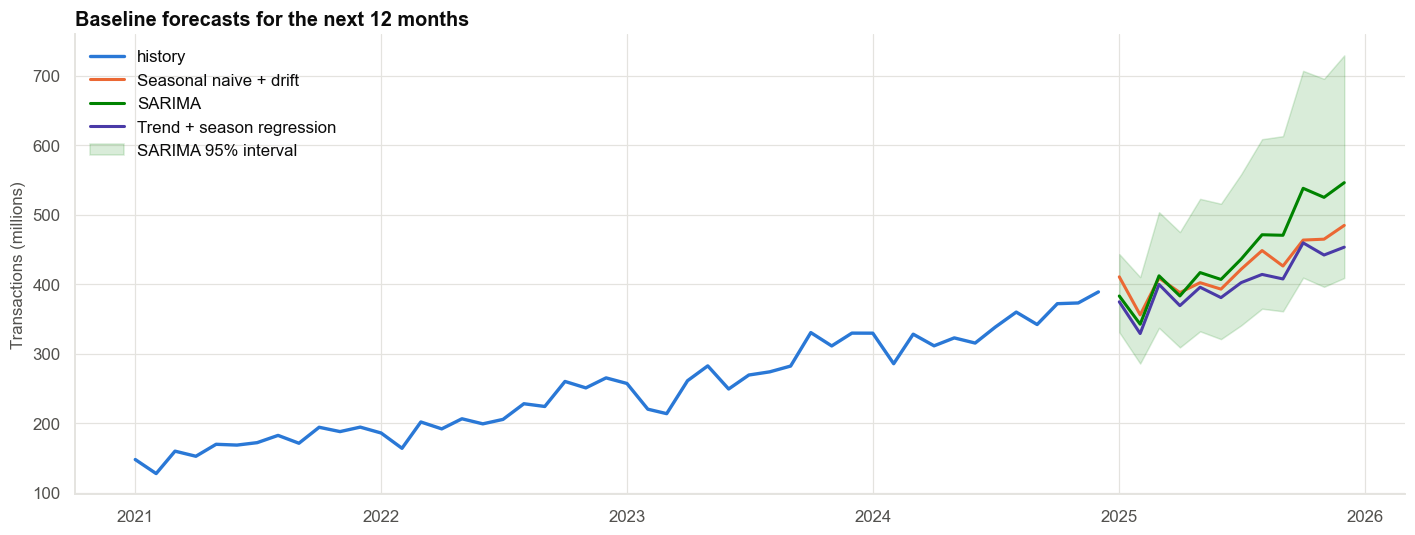

In [7]:
final_fc, final_sd = forecast_all(y)
fut_idx = final_fc["SARIMA"].index
tot24 = y.iloc[-12:].sum()
tot = pd.DataFrame({"2025 total (millions)": {k: np.exp(v).sum() for k, v in final_fc.items()}}).sort_values("2025 total (millions)")
tot.loc["Last year + 20% rule"] = 1.2 * tot24
tot["growth vs 2024"] = tot["2025 total (millions)"] / tot24 - 1
save_table(tot, "forecast_totals_2025", PATHS["tables"]); display(tot)
yoy_year = y.groupby(y.index.year).sum().pct_change().dropna()
print("Calendar-year growth of volume:", ", ".join(f"{k}: {v:.0%}" for k, v in yoy_year.items()))
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(y.index[-48:], y.iloc[-48:], color=PRIMARY, lw=2.2, label="history")
for k, c in [("Seasonal naive + drift", COLORS["orange"]), ("SARIMA", COLORS["green"]), ("Trend + season regression", COLORS["violet"] if "violet" in COLORS else COLORS["blue"])]:
    ax.plot(fut_idx, np.exp(final_fc[k]), color=c, lw=2, label=k)
sd = final_sd["SARIMA"]; ax.fill_between(fut_idx, np.exp(final_fc["SARIMA"] - 1.96 * sd), np.exp(final_fc["SARIMA"] + 1.96 * sd), color=COLORS["green"], alpha=0.15, label="SARIMA 95% interval")
ax.set(ylabel="Transactions (millions)", title="Baseline forecasts for the next 12 months"); ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); save_fig(fig, "fig06_forecast", PATHS["figures"]); plt.show()

**Observation.** Forecast totals for the next 12 months range from 4,827 million (regression) and 4,845 (Holt-Winters) to 5,067 (seasonal naive + drift) and 5,331 (SARIMA). "Last year plus 20%" gives 4,880: close to the regression (+1.1%).
But the calendar-year growth the rule relies on has declined every year since 2021 (51%, 27%, 27%, 24%), and the model trend is about 19% and falling.

**Interpretation.** The rule happens to land in the middle of the sensible range this year, but it has no mechanism for slowing growth: if growth continues to slow, it will overshoot by more each year.
A baseline model plus an explicit growth assumption is more defensible than a fixed percentage.

## Section 11 — Decision framework: describing and forecasting a time series

| Situation | Do this |
|---|---|
| Variance grows with the level | Take logs first |
| Trend present | Difference, or model the trend explicitly (and say which) |
| Seasonal pattern | Seasonal difference, month dummies, or a seasonal model; check the period |
| One-off events (outage, pandemic, policy change) | Flag, model with a dummy, or exclude; never let them define the seasonal pattern silently |
| Need a number to beat | Seasonal naive (with drift if growing) |
| Evaluating a forecast | Rolling origin, by time, same horizon as the decision; MAPE plus MASE |
| Quoting uncertainty | Check interval coverage in the rolling test before trusting the interval |
| Series is short (under about 3 seasonal cycles) | Prefer simple models; seasonal estimates are noisy |

**Never do:** randomly split a time series; compare a model's in-sample fit with a naive model's out-of-sample error; report only the best origin; apply an independence-based standard error to autocorrelated data.

## Section 12 — Grading against the truth (answer key and the revealed 2025 actuals)

2025 actual total: 4,822 million;  2024 total: 4,066;  actual growth 18.6%


,2025 total forecast,total error (%),MAPE (%)
model,,,
Naive,"4,666.5600",-3.2203,7.2546
Seasonal naive,"4,066.3200",-15.6687,15.5843
Seasonal naive + drift,"5,067.1328",5.0871,5.2044
Holt-Winters (damped),"4,844.5615",0.4712,2.4784
SARIMA,"5,330.6683",10.5526,10.1435
Trend + season regression,"4,827.0718",0.1085,1.5091
Last year + 20% rule,"4,879.5840",1.1976,NaN


SARIMA 95% interval contained 12 of 12 actual months
STL seasonal pattern, largest error 0.056 log points


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
true seasonal (log),-0.0125,-0.0825,0.0275,-0.0325,-0.0025,-0.0425,-0.0325,-0.0125,0.0075,0.0875,0.0575,0.0375
STL estimate,0.0051,-0.1386,0.0390,-0.0365,0.0118,-0.0580,-0.0134,0.0267,-0.0191,0.0892,0.0389,0.0548
error,0.0176,-0.0561,0.0115,-0.0040,0.0143,-0.0155,0.0191,0.0392,-0.0266,0.0017,-0.0186,0.0173


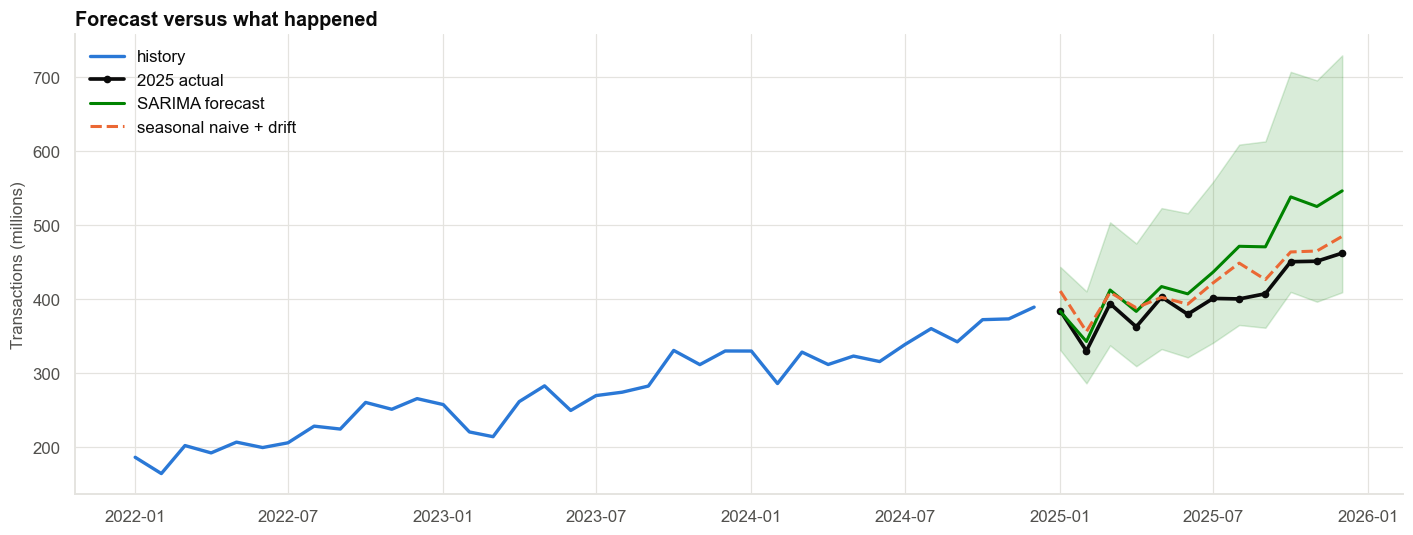

In [8]:
fut = pd.read_csv(PATHS["data"] / "future_actuals_teaching_only.csv", parse_dates=["month"]).set_index("month")["transactions_m"]
key = pd.read_csv(PATHS["data"] / "answer_key_teaching_only.csv", parse_dates=["month"]).set_index("month")
rows = []
for k, v in final_fc.items():
    p_ = np.exp(v)
    rows.append({"model": k, "2025 total forecast": p_.sum(), "total error (%)": 100 * (p_.sum() / fut.sum() - 1), "MAPE (%)": 100 * np.mean(np.abs(p_.to_numpy() - fut.to_numpy()) / fut.to_numpy())})
rows.append({"model": "Last year + 20% rule", "2025 total forecast": 1.2 * tot24, "total error (%)": 100 * (1.2 * tot24 / fut.sum() - 1), "MAPE (%)": np.nan})
final = pd.DataFrame(rows).set_index("model")
save_table(final, "final_holdout_grading", PATHS["tables"]); print(f"2025 actual total: {fut.sum():,.0f} million;  2024 total: {tot24:,.0f};  actual growth {fut.sum() / tot24 - 1:.1%}")
display(final)
sd_ = final_sd["SARIMA"]; lo, hi = np.exp(final_fc["SARIMA"] - 1.96 * sd_), np.exp(final_fc["SARIMA"] + 1.96 * sd_)
inside = ((fut.to_numpy() >= lo.to_numpy()) & (fut.to_numpy() <= hi.to_numpy())).sum()
print(f"SARIMA 95% interval contained {inside} of 12 actual months")
true_seas = key.loc[:"2024-12-01", "seasonal"].groupby(key.loc[:"2024-12-01"].index.month).mean()
est = comp["seasonal"].groupby(comp.index.month).mean()
gr = pd.DataFrame({"true seasonal (log)": true_seas - true_seas.mean(), "STL estimate": est - est.mean()})
gr["error"] = gr["STL estimate"] - gr["true seasonal (log)"]; gr.index = [pd.Timestamp(2000, m, 1).strftime("%b") for m in gr.index]
save_table(gr, "seasonal_estimate_vs_truth", PATHS["tables"]); print(f"STL seasonal pattern, largest error {gr['error'].abs().max():.3f} log points"); display(gr.T)
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(y.index[-36:], y.iloc[-36:], color=PRIMARY, lw=2.2, label="history")
ax.plot(fut.index, fut, color=INK, lw=2.4, marker="o", ms=4, label="2025 actual")
ax.plot(fut_idx, np.exp(final_fc["SARIMA"]), color=COLORS["green"], lw=2, label="SARIMA forecast"); ax.fill_between(fut_idx, lo, hi, color=COLORS["green"], alpha=0.15)
ax.plot(fut_idx, np.exp(final_fc["Seasonal naive + drift"]), color=COLORS["orange"], lw=2, ls="--", label="seasonal naive + drift")
ax.set(ylabel="Transactions (millions)", title="Forecast versus what happened"); ax.legend(frameon=False, loc="upper left")
fig.tight_layout(); save_fig(fig, "fig07_forecast_vs_actual", PATHS["figures"]); plt.show()

**Observation.** In 2025 the actual total was **4,822 million (+18.6%)**. Total error and MAPE for each forecast made on the data to Dec 2024:

| Model | 2025 total error | MAPE |
|---|---|---|
| Trend + season regression | **+0.1%** | **1.5%** |
| Holt-Winters (damped) | +0.5% | 2.5% |
| Seasonal naive + drift | +5.1% | 5.2% |
| Naive | −3.2% | 7.3% |
| SARIMA | +10.6% | 10.1% |
| Seasonal naive | −15.7% | 15.6% |
| Last year + 20% rule | +1.2% | n/a |

The 95% SARIMA interval contained all 12 actual months, because it is very wide, yet its point forecast was 10.6% too high. The STL seasonal pattern was within 0.06 log points of the truth in every month; its largest error is February (−0.056), where the calendar effect (fewer days) is part of the estimated seasonal component.

**Interpretation.** The ranking from the rolling-origin tests held in the genuinely unseen year: regression and Holt-Winters best, SARIMA and seasonal naive worst. The "last year plus 20%" rule was close, partly by luck of the year. A wide interval that contains the truth is not the same as an accurate forecast.

## Section 13 — Results

In [9]:
best = summ.index[0]
summary = pd.DataFrame({"Value": [
    f"{len(y)} months; trend growth {growth.iloc[0]:.0%} (early) to {growth.iloc[-1]:.0%} (late); December vs average month x{seas_tbl.loc['Dec', 'multiplier vs average month']:.2f}, October x{seas_tbl.loc['Oct', 'multiplier vs average month']:.2f}, February x{seas_tbl.loc['Feb', 'multiplier vs average month']:.2f}",
    f"ADF p-values: raw {tests.iloc[0, 1]:.2f}, log {tests.iloc[1, 1]:.2f}, log first diff {tests.iloc[2, 1]:.3f}, log first + seasonal diff {tests.iloc[4, 1]:.3g}",
    f"rolling-origin MAPE: " + "; ".join(f"{k} {v:.1f}%" for k, v in summ["MAPE (%)"].items()),
    f"interval coverage (95% nominal): " + "; ".join(f"{k} {v:.0%}" for k, v in cv[0.95].items()),
    f"2025 forecast total: SARIMA {tot.loc['SARIMA', '2025 total (millions)']:,.0f}; 20% rule {1.2 * tot24:,.0f}; 2025 actual {fut.sum():,.0f}",
]}, index=["History", "Stationarity", "Accuracy", "Intervals", "2025"])
save_table(summary, "results_summary", PATHS["tables"]); summary

,Value
History,108 months; trend growth 52% (early) to 19% (l...
Stationarity,"ADF p-values: raw 1.00, log 0.05, log first di..."
Accuracy,rolling-origin MAPE: Trend + season regression...
Intervals,interval coverage (95% nominal): SARIMA 96%; T...
2025,"2025 forecast total: SARIMA 5,331; 20% rule 4,..."


## Section 14 — Interpretation

- **The series is a slowing exponential trend with stable seasonality and two shocks.** Trend growth fell from 52% to 19%.
- **Ordinary statistics fail:** the series is non-stationary and autocorrelated (lag-1 0.61), so means, correlations and naive standard errors mislead; split by time.
- **Simple models win:** a trend plus seasonal-dummy regression beat SARIMA and Holt-Winters in the rolling tests and in 2025. Seasonal naive is a poor baseline for fast-growing data.
- **Say how wrong you could be:** the rolling-origin interval coverage was about right (95-96%), but the intervals are wide (the SARIMA interval contained every 2025 month despite a 10% biased point forecast).

## Section 15 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "Volume has a stable seasonal pattern: October about 9% above an average month, February about 13% below." | "Volume grows 20% a year." (Growth fell from 52% to 19%.) |
| "A trend-plus-season regression forecast 2025 at 4,827 million; in backtests it was within about 4% a month." | "The forecast is exact." (Rolling MAPE 4%; some origins much worse.) |
| "The 20% rule gives a figure within about 1% of the best model this year." | "The rule is validated." (It ignores the slowing trend.) |
| "COVID reduced volume to about 74% of expected for four months." | "The shocks do not matter" (they change the seasonal estimates and any forecast that spans them). |

## Section 16 — Business interpretation

- Plan capacity on the **regression forecast with an interval**, and review quarterly against actuals.
- Staff and provision for the **October-December peak** (about +9% in October) and the **February trough**.
- Replace "last year + 20%" with a **model-based baseline plus an explicit growth scenario** (e.g. 12%, 18%, 24%).
- Treat **one-off outages and pandemics as scenarios**, not as part of the trend.

## Section 17 — Limitations

- 108 months give nine usable years of seasonality; seasonal estimates are noisy.
- Rolling origins overlap, so the nine evaluation windows are not independent.
- Interval coverage is estimated from nine origins only.
- The generating process is simple and known; real series have changing seasonality and new shocks.
- Synthetic data.

## Section 18 — Final recommendation

> **Use a trend-plus-seasonal regression (or damped Holt-Winters) as the baseline forecast, publish its 95% interval, and compare every fancier model with it in a rolling-origin test.** Expect about 4% average error month by month.
> Do not use a fixed growth rule; use a growth scenario range of about 12% to 24%.

## Section 19 — What would I do next?

1. Add **explanatory variables** (merchant count, marketing, festival dates that move) and compare with the baselines.
2. Move to a **hierarchical forecast** (by product or channel) that adds up to the total.
3. Use **more origins** and a longer history to check the stability of the model ranking.
4. Build **scenario forecasts** for shocks (outage, regulation) with explicit assumptions.
5. Continue to **Case 26** (time until an event: collections and SLA).